In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv('dataset/Mall_Customers.csv')
df.head(2)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81


In [3]:
# ohe = OneHotEncoder(sparse_output = False)
# encoded = ohe.fit_transform(df[['Gender']])
# gender_df = pd.DataFrame(encoded, columns = ohe.get_feature_names_out(['Gender']))
# df[['Gender_Female', 'Gender_Male']] = gender_df

In [4]:
le = LabelEncoder()
df['Gender_Id'] = le.fit_transform(df['Gender'])

## Features

In [65]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

## Scaling

In [66]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)

## Elbow Method

In [67]:
import warnings
warnings.filterwarnings('ignore')

In [68]:
k_range = range(1, 21)
error_rate = []

for i in k_range:
    kmeans = KMeans(n_clusters = i)
    kmeans.fit_predict(X_scale)
    error_rate.append(kmeans.inertia_)

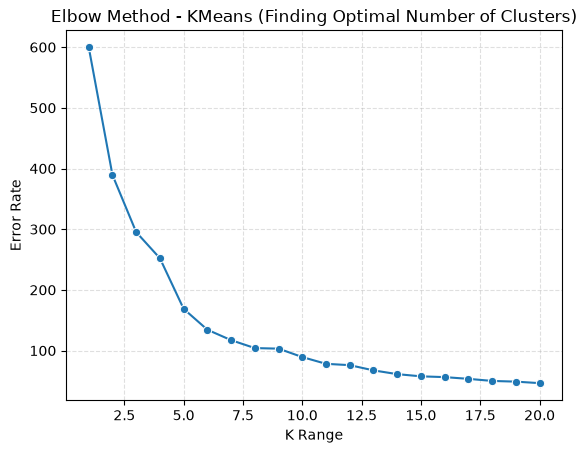

In [69]:
sns.lineplot(x=k_range, y=error_rate, marker='o')
plt.xlabel('K Range')
plt.ylabel('Error Rate')
plt.title('Elbow Method - KMeans (Finding Optimal Number of Clusters)')
plt.grid(linestyle='--', alpha=0.4)
plt.show()

In [70]:
k = 5
model = KMeans(n_clusters=k)
clusters = model.fit_predict(X_scale)
df['clusters'] = clusters

In [71]:
sc = silhouette_score(X_scale, labels=clusters)
print(sc)

0.361814032768262


## Visualization

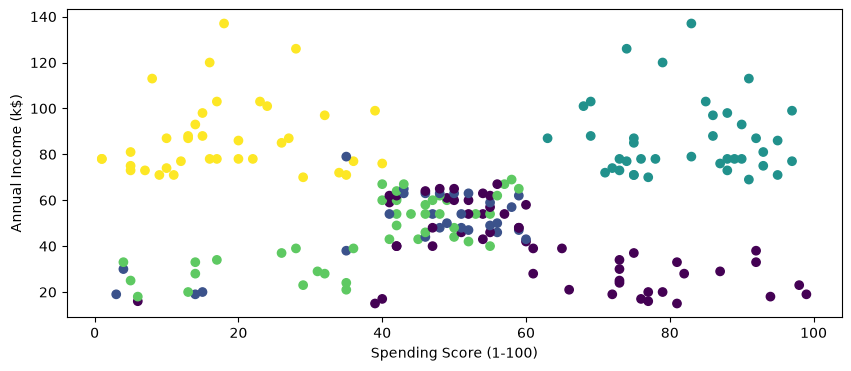

In [84]:
plt.figure(figsize=(10, 4))
plt.scatter(df['Spending Score (1-100)'], df['Annual Income (k$)'], c=df['clusters'])
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Annual Income (k$)')
plt.show()

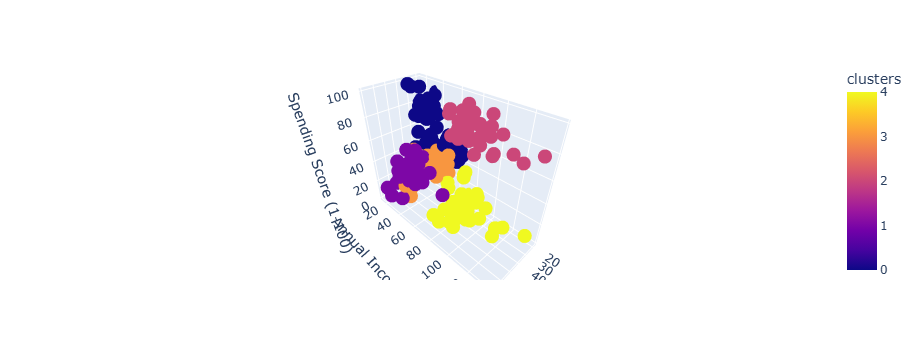

In [85]:
import plotly.express as px

fig = px.scatter_3d(
    df, 
    x = 'Age', 
    y = 'Annual Income (k$)',
    z = 'Spending Score (1-100)',
    color = 'clusters'
)
fig.show()

## Principle Component Analysis

In [74]:
from sklearn.decomposition import PCA

In [75]:
# n_components -> Number of Features
pca = PCA(n_components = len(features))

In [76]:
# Covariance Calculation
pca_scale = pca.fit_transform(X_scale)

In [79]:
loadings = pd.DataFrame(
    pca.components_,
    index=features,
    columns = [f'PC{i+1}' for i in range(3)]
)
loadings

,PC1,PC2,PC3
Age,0.706382,-0.048024,-0.706199
Annual Income (k$),0.030141,0.998832,-0.037775
Spending Score (1-100),0.707188,0.005398,0.707005


In [ ]:
'''
PC1 -> Higher -> Feature -> X-axis
PC2 -> Higher -> Feature -> Y-axis

X-axis -> Age, Gender_Id
Y-axis -> Annual Income (k$), Spending Score (1-100)
'''

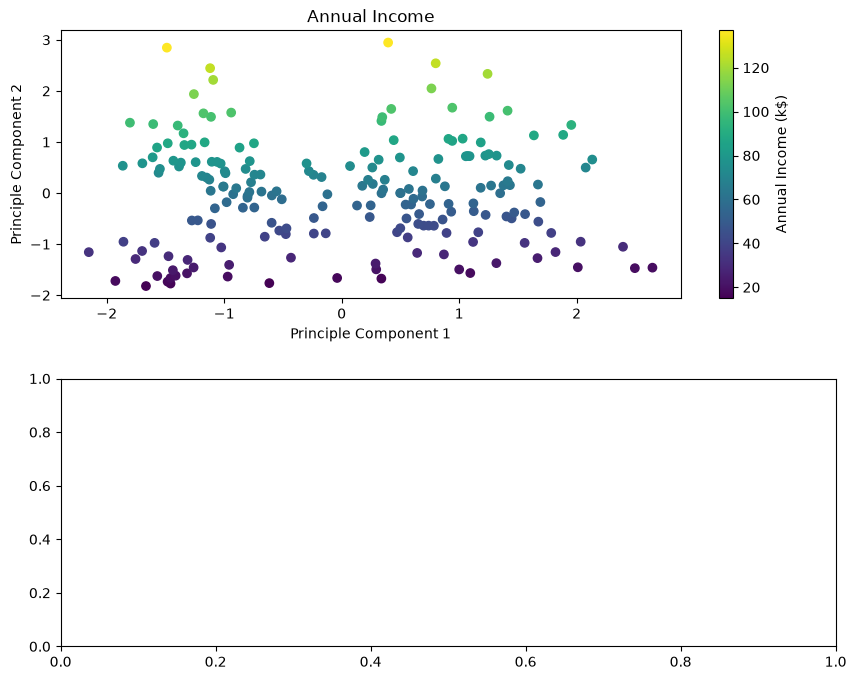

In [80]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
plt.subplots_adjust(hspace = 0.3)
color = 'Annual Income (k$)'
ax1 = axes[0]
scatter = ax1.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color])
plt.colorbar(scatter, label=color)
ax1.set_xlabel('Principle Component 1')
ax1.set_ylabel('Principle Component 2')
ax1.set_title('Annual Income')

# color2 = 'Spending Score (1-100)'
# ax2 = axes[1]
# scatter = ax2.scatter(pca_scale[:,0], pca_scale[:,1], c=df[color2])
# plt.colorbar(scatter, label=color2)
# ax2.set_xlabel('Principle Component 1')
# ax2.set_ylabel('Principle Component 2')
# ax2.set_title('Spending Score')

# plt.savefig('pca.png')
plt.show()